In [1]:
!pip install -q pandas scikit-learn matplotlib seaborn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [2]:
from google.colab import files

uploaded = files.upload()

filename = list(uploaded.keys())[0]
df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
df.head()

Saving fake reviews dataset.csv to fake reviews dataset.csv
Dataset loaded successfully!
Shape: (40432, 4)


,category,rating,label,text_
0,Home_and_Kitchen_5,5.0,CG,"Love this! Well made, sturdy, and very comfor..."
1,Home_and_Kitchen_5,5.0,CG,"love it, a great upgrade from the original. I..."
2,Home_and_Kitchen_5,5.0,CG,This pillow saved my back. I love the look and...
3,Home_and_Kitchen_5,1.0,CG,"Missing information on how to use it, but it i..."
4,Home_and_Kitchen_5,5.0,CG,Very nice set. Good quality. We have had the s...


In [3]:
print("Columns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nLabel distribution:")
print(df['label'].value_counts())

Columns:
['category', 'rating', 'label', 'text_']

Missing values:
category    0
rating      0
label       0
text_       0
dtype: int64

Label distribution:
label
CG    20216
OR    20216
Name: count, dtype: int64


### 3. Clean the Review Text

This section focuses on preparing the `text_` column for machine learning by performing several cleaning operations:
- Handling potential missing values.
- Converting all text to lowercase to ensure consistency.
- Removing extra spaces.
- Removing special characters and punctuation to reduce noise.

In [4]:
# Fill any potential missing values in the 'text_' column with an empty string
df['text_'] = df['text_'].fillna('')

# Convert text to lowercase
df['text_'] = df['text_'].str.lower()

# Remove unnecessary spaces (leading, trailing, and multiple internal spaces)
df['text_'] = df['text_'].str.strip().str.replace('\s+', ' ')

# Remove special characters and punctuation (keeping only alphanumeric characters and spaces)
df['text_'] = df['text_'].str.replace('[^a-zA-Z0-9\s]', '', regex=True)

print("Review text cleaned successfully!")

# Display the first few rows with cleaned text
print("\nDataFrame after text cleaning:")
display(df[['text_', 'label']].head())

<>:8: SyntaxWarning: invalid escape sequence '\s'
<>:11: SyntaxWarning: invalid escape sequence '\s'
<>:8: SyntaxWarning: invalid escape sequence '\s'
<>:11: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_5340/1028963009.py:8: SyntaxWarning: invalid escape sequence '\s'
  df['text_'] = df['text_'].str.strip().str.replace('\s+', ' ')
/tmp/ipykernel_5340/1028963009.py:11: SyntaxWarning: invalid escape sequence '\s'
  df['text_'] = df['text_'].str.replace('[^a-zA-Z0-9\s]', '', regex=True)


Review text cleaned successfully!

DataFrame after text cleaning:


,text_,label
0,love this well made sturdy and very comfortab...,CG
1,love it a great upgrade from the original ive...,CG
2,this pillow saved my back i love the look and ...,CG
3,missing information on how to use it but it is...,CG
4,very nice set good quality we have had the set...,CG


### 4. Convert Target Labels to Binary Classes

This step converts the categorical `label` column into a numerical binary format, which is required for machine learning models. We will map:
- `OR` (Original Review) to `1` (Fake Review)
- `CG` (Computer Generated) to `0` (Genuine Review)

In [5]:
# Map 'OR' to 1 (Fake Review) and 'CG' to 0 (Genuine Review)
df['label'] = df['label'].map({'OR': 1, 'CG': 0})

print("Labels converted to binary classes successfully!")

# Display the updated label distribution
print("\nUpdated Label distribution:")
print(df['label'].value_counts())

# Display the first few rows with the new binary labels
print("\nDataFrame after label conversion:")
display(df[['text_', 'label']].head())

Labels converted to binary classes successfully!

Updated Label distribution:
label
0    20216
1    20216
Name: count, dtype: int64

DataFrame after label conversion:


,text_,label
0,love this well made sturdy and very comfortab...,0
1,love it a great upgrade from the original ive...,0
2,this pillow saved my back i love the look and ...,0
3,missing information on how to use it but it is...,0
4,very nice set good quality we have had the set...,0


### 5. Split Data into Training and Testing Sets

To evaluate our model's performance on unseen data, we will split the dataset into two parts:
- **Training Set (80%)**: Used to train the machine learning model.
- **Testing Set (20%)**: Used to assess the model's performance on new, unseen data.

We will use `train_test_split` from `sklearn.model_selection` for this purpose.

In [6]:
# Define features (X) and target (y)
X = df['text_']
y = df['label']

# Split the dataset into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Dataset split into training and testing sets successfully!")
print(f"Training set size: {len(X_train)} samples")
print(f"Testing set size: {len(X_test)} samples")

print("\nTraining label distribution:")
print(y_train.value_counts(normalize=True))
print("\nTesting label distribution:")
print(y_test.value_counts(normalize=True))

Dataset split into training and testing sets successfully!
Training set size: 32345 samples
Testing set size: 8087 samples

Training label distribution:
label
1    0.500015
0    0.499985
Name: proportion, dtype: float64

Testing label distribution:
label
0    0.500062
1    0.499938
Name: proportion, dtype: float64


### 6. TF-IDF Vectorization for Text Feature Extraction

Before training a machine learning model, text data needs to be converted into numerical features. TF-IDF (Term Frequency-Inverse Document Frequency) is a widely used technique for this purpose.

- **TF (Term Frequency)**: Measures how frequently a term appears in a document.
- **IDF (Inverse Document Frequency)**: Measures how important a term is across the entire corpus.

`TfidfVectorizer` from `sklearn.feature_extraction.text` will be used to transform our text data.

In [7]:
# Initialize TfidfVectorizer
tfidf_vectorizer = TfidfVectorizer(max_features=5000) # Limiting to 5000 features for efficiency

# Fit the vectorizer on the training data and transform both training and testing data
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

print("TF-IDF Vectorization completed successfully!")
print(f"Shape of X_train_tfidf: {X_train_tfidf.shape}")
print(f"Shape of X_test_tfidf: {X_test_tfidf.shape}")

TF-IDF Vectorization completed successfully!
Shape of X_train_tfidf: (32345, 5000)
Shape of X_test_tfidf: (8087, 5000)


### 7. Train a Logistic Regression Model

Logistic Regression is a linear model used for binary classification. Despite its name, it is a classification algorithm rather than a regression algorithm. It works by estimating the probability of a given instance belonging to a particular class.

We will train a `LogisticRegression` model from `sklearn.linear_model` using our TF-IDF transformed training data.

In [8]:
# Initialize the Logistic Regression model
logistic_model = LogisticRegression(solver='liblinear', random_state=42)

# Train the model using the TF-IDF transformed training data
logistic_model.fit(X_train_tfidf, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


### 8. Evaluate the Model

After training the model, it's crucial to evaluate its performance on the test set. We will use several metrics commonly employed in binary classification:

- **Accuracy**: The proportion of correctly classified instances.
- **Precision**: The proportion of true positive predictions among all positive predictions. It measures the model's ability to avoid false positives.
- ****Recall (Sensitivity)**: The proportion of true positive predictions among all actual positive instances. It measures the model's ability to find all positive samples.
- **F1-Score**: The harmonic mean of precision and recall. It provides a single score that balances both metrics.
- **Confusion Matrix**: A table that describes the performance of a classification model on a set of test data for which the true values are known. It helps visualize the types of errors made.

We will also display the confusion matrix using a heatmap for better visualization.

Model Evaluation Results:
Accuracy: 0.9016

Classification Report:
               precision    recall  f1-score   support

           0       0.91      0.89      0.90      4044
           1       0.90      0.91      0.90      4043

    accuracy                           0.90      8087
   macro avg       0.90      0.90      0.90      8087
weighted avg       0.90      0.90      0.90      8087


Confusion Matrix:
 [[3613  431]
 [ 365 3678]]


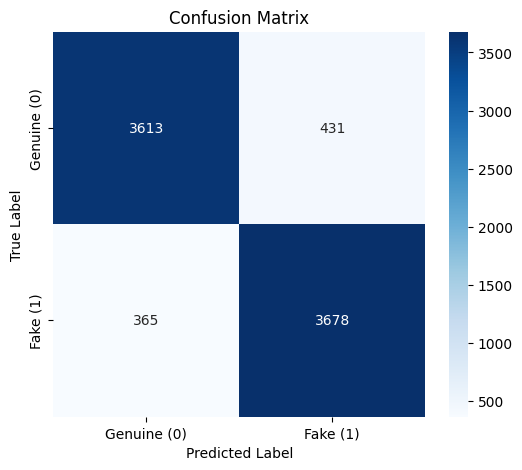

In [9]:
# Predict labels on the test set
y_pred = logistic_model.predict(X_test_tfidf)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)

print("Model Evaluation Results:")
print(f"Accuracy: {accuracy:.4f}")
print("\nClassification Report:\n", report)
print("\nConfusion Matrix:\n", conf_matrix)

# Visualize the Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Genuine (0)', 'Fake (1)'],
            yticklabels=['Genuine (0)', 'Fake (1)'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

### 9. Show Class Distribution Using a Graph

Visualizing the class distribution provides a clear understanding of the balance between the two classes (Genuine and Fake reviews) in our dataset. A balanced dataset helps in training a fair model, while an imbalanced one might require special handling.

We will use a bar plot to display the counts of each class.

/tmp/ipykernel_5340/652288897.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='label', data=df, palette='viridis')


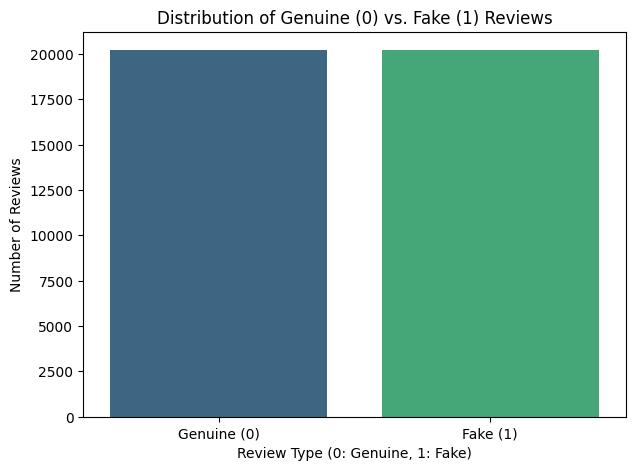

In [10]:
# Plotting the class distribution
plt.figure(figsize=(7, 5))
sns.countplot(x='label', data=df, palette='viridis')
plt.title('Distribution of Genuine (0) vs. Fake (1) Reviews')
plt.xlabel('Review Type (0: Genuine, 1: Fake)')
plt.ylabel('Number of Reviews')
plt.xticks([0, 1], ['Genuine (0)', 'Fake (1)'])
plt.show()

### 10. Print a Few Sample Predictions

To better understand how our model is performing, let's examine some sample reviews from the test set and see what the model predicts, alongside the actual labels.

In [11]:
print("Sample Predictions:")

sample_indices = [0, 1, 2, 3, 4] # Get first 5 samples from the test set

for i in sample_indices:
    review = X_test.iloc[i]
    actual_label = y_test.iloc[i]
    predicted_label = y_pred[i]

    # Get prediction probabilities
    review_tfidf = tfidf_vectorizer.transform([review])
    probabilities = logistic_model.predict_proba(review_tfidf)[0]
    confidence = max(probabilities) * 100

    print(f"\nReview: {review[:100]}...") # Truncate review for display
    print(f"Actual Label: {actual_label} ({'Fake' if actual_label == 1 else 'Genuine'})")
    print(f"Predicted Label: {predicted_label} ({'Fake' if predicted_label == 1 else 'Genuine'})")
    print(f"Confidence: {confidence:.2f}%")

Sample Predictions:

Review: incredibly horrible quality and detail period seriously its nothing like the picture...
Actual Label: 1 (Fake)
Predicted Label: 1 (Fake)
Confidence: 87.10%

Review: minimal attractactant if any cats are very picky...
Actual Label: 0 (Genuine)
Predicted Label: 1 (Fake)
Confidence: 59.11%

Review: promptly delivers no qualms about anything else

great boot i wear it all the time now

it works for...
Actual Label: 1 (Fake)
Predicted Label: 1 (Fake)
Confidence: 87.34%

Review: what can i say another word about the book  i really enjoyed this book  i am a big fan of the harry ...
Actual Label: 0 (Genuine)
Predicted Label: 0 (Genuine)
Confidence: 57.02%

Review: serious offgassing ugh  not only do you have to clean the area around the...
Actual Label: 0 (Genuine)
Predicted Label: 1 (Fake)
Confidence: 52.61%


### 11. Create a Prediction Function for New Reviews

This function will allow you to input a new product review and get a real-time prediction from our trained Logistic Regression model. It will output:
- Whether the review is predicted as 'FAKE REVIEW' or 'GENUINE REVIEW'.
- The model's confidence in its prediction.

In [12]:
def predict_new_review(review_text):
    # 1. Clean the input review text
    cleaned_review = review_text.lower() # Convert to lowercase
    cleaned_review = cleaned_review.strip().replace('\s+', ' ') # Remove extra spaces
    cleaned_review = re.sub(r'[^a-zA-Z0-9\s]', '', cleaned_review) # Remove special characters

    # 2. Transform the cleaned review using the trained TF-IDF vectorizer
    review_tfidf = tfidf_vectorizer.transform([cleaned_review])

    # 3. Get the prediction (0 or 1)
    prediction = logistic_model.predict(review_tfidf)[0]

    # 4. Get the prediction probabilities
    probabilities = logistic_model.predict_proba(review_tfidf)[0]

    # 5. Determine the confidence percentage
    confidence = max(probabilities) * 100

    # 6. Interpret the prediction
    if prediction == 1:
        result = "FAKE REVIEW"
    else:
        result = "GENUINE REVIEW"

    print(f"Predicted: {result}")
    print(f"Confidence: {confidence:.2f}%")

import re # Import re module for regular expressions

print("Prediction function created successfully!")

# Example usage of the function:
# new_review_1 = "This product is absolutely amazing! Best purchase ever!"
# predict_new_review(new_review_1)

# new_review_2 = "Buyer beware! This item broke after one use. Total scam."
# predict_new_review(new_review_2)


Prediction function created successfully!


<>:4: SyntaxWarning: invalid escape sequence '\s'
<>:4: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_5340/2949116299.py:4: SyntaxWarning: invalid escape sequence '\s'
  cleaned_review = cleaned_review.strip().replace('\s+', ' ') # Remove extra spaces


### 12. Project Explanation and Summary

#### Problem Statement:

The project addresses the critical issue of **fake product reviews** in e-commerce. Fake reviews can mislead consumers, damage brand reputation, and distort market perceptions. The goal is to develop an AI-based system to accurately detect and classify product reviews as either genuine or fake.

#### Dataset:

The dataset used for this project contains product reviews, each labeled as either 'CG' (Computer Generated, representing fake reviews) or 'OR' (Original Review, representing genuine reviews). Key columns include `text_` (the review content) and `label` (the classification of the review).

#### Preprocessing:

Before model training, the raw text data underwent several preprocessing steps to ensure quality and consistency:
1.  **Handling Missing Values**: Any empty review texts were filled to prevent errors.
2.  **Lowercase Conversion**: All text was converted to lowercase to treat words like "Great" and "great" as the same.
3.  **Space Normalization**: Extra spaces were removed to standardize the text.
4.  **Special Character Removal**: Punctuation and special characters were removed to focus on alphanumeric content, reducing noise.
5.  **Label Encoding**: The categorical labels ('CG' and 'OR') were converted into a binary numerical format (0 for Genuine, 1 for Fake), suitable for binary classification models.

#### TF-IDF (Term Frequency-Inverse Document Frequency):

TF-IDF is a numerical statistic that reflects how important a word is to a document in a collection or corpus. It is used to transform text data into a numerical format that machine learning models can understand. Words that are frequent in a document but rare across the entire corpus receive higher TF-IDF scores, indicating their significance.

#### Logistic Regression:

Logistic Regression is a statistical model primarily used for binary classification. Despite its name, it predicts the probability of a binary outcome (e.g., 0 or 1). It uses a logistic function to estimate probabilities and classify instances based on a threshold. It's a simple yet effective algorithm, often used as a baseline for classification tasks.

#### Binary Classification:

Binary classification is a type of supervised learning problem where the goal is to classify data points into one of two categories (classes). In this project, the two classes are "Genuine Review" and "Fake Review."

#### Evaluation Metrics:

To assess the model's performance, several metrics were used:
-   **Accuracy**: The overall proportion of correct predictions.
-   **Precision**: The ability of the model to not label as positive a sample that is negative (i.e., minimizing false positives).
-   **Recall**: The ability of the model to find all the positive samples (i.e., minimizing false negatives).
-   **F1-Score**: The harmonic mean of precision and recall, providing a balanced measure of performance.
-   **Confusion Matrix**: A table showing the counts of true positives, true negatives, false positives, and false negatives, offering a detailed breakdown of classification errors.

#### Final Prediction Process:

The final prediction process involves:
1.  **Text Cleaning**: Any new review text is cleaned using the same preprocessing steps applied to the training data.
2.  **TF-IDF Transformation**: The cleaned text is converted into a numerical vector using the pre-trained TF-IDF vectorizer.
3.  **Model Prediction**: The Logistic Regression model then uses this vector to predict the likelihood of the review being fake or genuine.
4.  **Confidence Score**: The model also provides a confidence score, indicating the probability of its prediction, which helps in understanding the model's certainty.